# Scary Stochastics, Week 4: Gibbs Sampling
## Notebook 2 of 3 — Creature from the Black Lagoon

This notebook is self-contained (same setup as Notebook 1). The Creature rarely strays far from the water, so attack distances from shore pile up near zero with a thin tail running inland — a natural fit for a **Gamma distribution**, which has two unknowns: a shape and a rate.

Gibbs works just like before, with one wrinkle: given the shape, the rate's conditional distribution is a textbook Gamma, but given the rate, the shape's conditional isn't any named distribution. The fix is **griddy Gibbs**: compute the conditional's probability on a fine grid of candidate shape values, then sample from that grid.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import gammaln

# Monster palette (extends the series palette with one color per monster)
PALETTE = {
    "red":     "#C8102E",  # candy red - "true value" markers
    "orange":  "#E8741C",
    "rust":    "#B5451B",
    "purple":  "#3B2145",
    "mustard": "#D9A404",
    "magenta": "#B5338A",  # slime magenta - The Blob
    "teal":    "#2A7F7F",  # lagoon teal - Creature from the Black Lagoon
    "silver":  "#9AA5B4",  # moonlight silver - Werewolf
    "black":   "#1B1B1B",
    "cream":   "#FBF3E1",
}

N_ITER = 5000    # Gibbs iterations per monster
BURN_IN = 500    # early iterations we throw away

plt.rcParams.update({
    "figure.facecolor": PALETTE["cream"],
    "axes.facecolor": PALETTE["cream"],
    "axes.edgecolor": PALETTE["black"],
    "text.color": PALETTE["black"],
    "axes.labelcolor": PALETTE["black"],
    "xtick.color": PALETTE["black"],
    "ytick.color": PALETTE["black"],
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
})

def summarize(samples, truths):
    """Posterior summary (after burn-in) next to the true values used to simulate the data."""
    rows = []
    for name, s in samples.items():
        s = np.asarray(s)[BURN_IN:]
        rows.append([name, truths[name], s.mean(), np.percentile(s, 2.5), np.percentile(s, 97.5)])
    return pd.DataFrame(rows, columns=["Parameter", "True", "Post. mean", "2.5%", "97.5%"]).round(2)

### Simulate the data and run the sampler

True values: shape 2.0, rate 0.25 (an average attack 8 meters from shore).

In [2]:
# ---- CREATURE FROM THE BLACK LAGOON: how far from shore do attacks happen? ----
np.random.seed(2)
TRUE_SHAPE, TRUE_RATE = 2.0, 0.25    # average attack is 8 m from shore
creature_x = np.random.gamma(TRUE_SHAPE, 1 / TRUE_RATE, size=80)

n_c = len(creature_x)
sum_x, sum_logx = creature_x.sum(), np.log(creature_x).sum()
a0, b0 = 1.0, 0.05                       # weak prior on the rate
shape_grid = np.linspace(0.05, 10, 400)  # candidate shape values for the grid step

shape, rate = 8.0, 2.0                   # deliberately far-off starting point
creature_shape, creature_rate = [], []
for i in range(N_ITER):
    # Step 1: draw the rate given the shape (a textbook Gamma)
    rate = np.random.gamma(a0 + n_c * shape, 1 / (b0 + sum_x))
    # Step 2: draw the shape given the rate. This conditional is NOT a textbook
    # distribution, so we compute it on a grid and sample from that ("griddy Gibbs").
    logp = shape_grid * (n_c * np.log(rate) + sum_logx) - n_c * gammaln(shape_grid) - 0.1 * shape_grid
    p = np.exp(logp - logp.max())
    p /= p.sum()
    shape = np.random.choice(shape_grid, p=p) + np.random.uniform(-0.0125, 0.0125)
    creature_shape.append(shape)
    creature_rate.append(rate)

creature_shape, creature_rate = np.array(creature_shape), np.array(creature_rate)

summarize({"Shape": creature_shape, "Rate": creature_rate},
          {"Shape": TRUE_SHAPE, "Rate": TRUE_RATE})

,Parameter,True,Post. mean,2.5%,97.5%
0,Shape,2.00,1.77,1.29,2.29
1,Rate,0.25,0.24,0.16,0.32


### Visual 3 — Did the sampler settle down?

Trace plots show each parameter's draws over time. The shaded region is burn-in, discarded because the chain started from a deliberately bad guess. After that, the draws wander around a stable region — the sign we want to see.

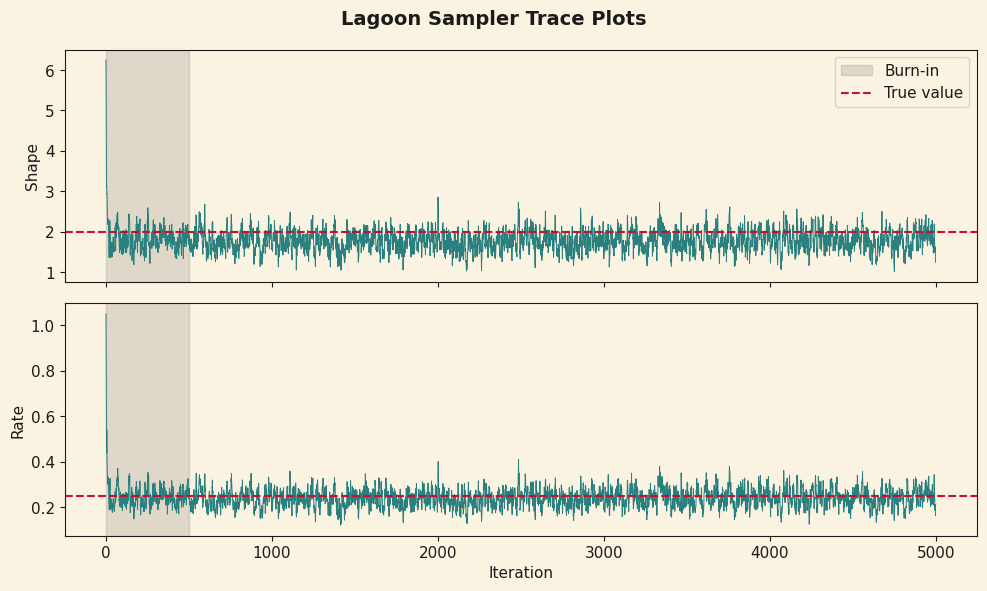

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, draws, truth, label in zip(axes, [creature_shape, creature_rate],
                                   [TRUE_SHAPE, TRUE_RATE], ["Shape", "Rate"]):
    ax.plot(draws, color=PALETTE["teal"], linewidth=0.7)
    ax.axvspan(0, BURN_IN, color=PALETTE["black"], alpha=0.12, label="Burn-in")
    ax.axhline(truth, color=PALETTE["red"], linestyle="--", linewidth=1.5, label="True value")
    ax.set_ylabel(label)
axes[0].legend(loc="upper right")
axes[1].set_xlabel("Iteration")
fig.suptitle("Lagoon Sampler Trace Plots", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("03_lagoon_traces.png", dpi=150, facecolor=PALETTE["cream"])
plt.show()

### Visual 4 — How well does the fitted distribution match?

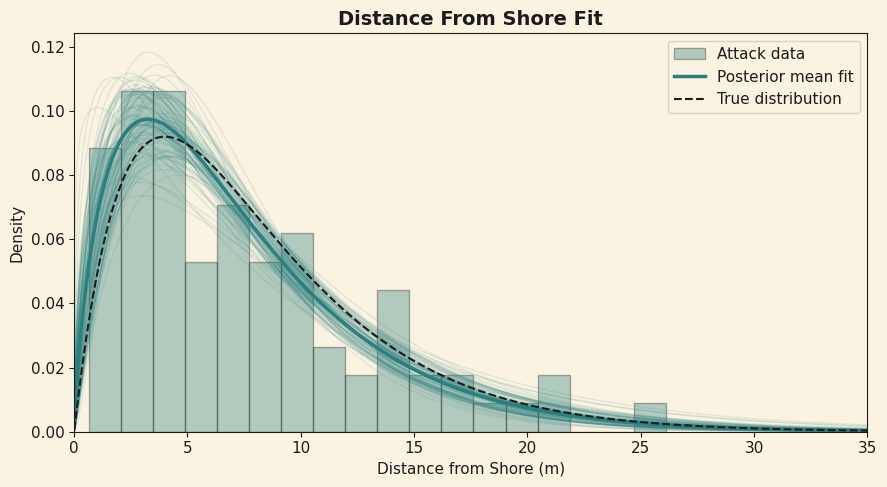

In [4]:
x_grid = np.linspace(0.01, 40, 400)
rng_idx = np.random.choice(np.arange(BURN_IN, N_ITER), size=100, replace=False)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(creature_x, bins=18, density=True, color=PALETTE["teal"], alpha=0.35,
        edgecolor=PALETTE["black"], label="Attack data")
for i in rng_idx:
    ax.plot(x_grid, stats.gamma.pdf(x_grid, creature_shape[i], scale=1 / creature_rate[i]),
            color=PALETTE["teal"], alpha=0.12, linewidth=1)
ax.plot(x_grid, stats.gamma.pdf(x_grid, creature_shape[BURN_IN:].mean(),
                                scale=1 / creature_rate[BURN_IN:].mean()),
        color=PALETTE["teal"], linewidth=2.5, label="Posterior mean fit")
ax.plot(x_grid, stats.gamma.pdf(x_grid, TRUE_SHAPE, scale=1 / TRUE_RATE),
        color=PALETTE["black"], linestyle="--", linewidth=1.5, label="True distribution")
ax.set_xlim(0, 35)
ax.set_xlabel("Distance from Shore (m)")
ax.set_ylabel("Density")
ax.set_title("Distance From Shore Fit")
ax.legend()
plt.tight_layout()
plt.savefig("04_shore_distance_fit.png", dpi=150, facecolor=PALETTE["cream"])
plt.show()

### Up next

Notebook 3 handles the Werewolf, where one of the unknowns is a *night* — a discrete quantity — and then puts all three monsters side by side.